In the previous chapters we learned that it can be beneficial to write performance-critical (parts of) image analysis algorithms in a compiled language such as C. This chapter explains some details about the C language that you should know to write an image filter, such as the `bilateral_filter` from the previous chapter, yourself.

We'll do this by taking a closer look at the code for the `bilateral_filter`.

## The C Syntax

### Source Files, Header Files, and Includes

Whereas Python source files have the extension `.py`, C code source files typically have the extension `.c`. These files contain the implementation, or *definition*, of functions. There are also files with the extension `.h`, which are called *header files*. These header files contain function and datatype *declarations*, i.e. the C-style interface. A header files like the one below just tells: there will be a function called `bilater_filter` that returns an `int` and expects five arguments (a pointer to a `double`, a `size_t`, two `double`s, and another pointer to a `double`).

::: {#lst-example}

```c
#include <stddef.h>  // Provides size_t

//  Applies a 1-dimensional bilateral filter.
//  Returns 0 on success, -1 on invalid arguments.
int bilateral_filter(
    double *data,    // Pointer to a 1-dimensional array.
    size_t length,   // Number of elements in 'data'.
    double sigma_s,  // The spatial standard deviation of the spatial kernel (sample distance).
    double sigma_r,  // The standard deviation of the range kernel (sample values).
    double *result   // Pointer to the output array (must have at least 'length' elements).
);
```

The header file `filters.h`

:::

Similar to Python, C can import functions from other libraries. This is done by *including* the header files of these libraries. The line `#include <stddef.h>` literally means: *insert the contents of the file stddef.h at this point*. The syntax `#include <stddef.h>`, with `<>`, will search for a standard or system header file named `stddef.h`. The syntax `#include "filters.h"`, with `""`, will search for a file named `filters.h` in your own project.

The source file for our `bilateral_filter`, named e.g. `filters.c`, includes `stddef.h`, which provides the datatype `size_t`. It also includes `math.h`, which provides the declaration for the `exp()` function. It is also common practice to include our own header file, `filters.h`, because we can use this header file to declare e.g. custom datatypes.

### Functions

The general syntax for a function definition in C is:

```c
return_type function_name(arguments) {
    // Function body
    return value;
}
```

For example:

```c
double square(double x)
{
    return x * x;
}
```

In this example `double` is the return type, and `square` is the function name. The function has only one parameter, `x`, of type `double`.

The *body* of the function must be given between curly brackets `{}`. Whereas Python uses 4 spaces of indentation to distinguish between a function body and other code, C does *not* take indentation or linebreaks into account. In C, indentation and linebreaks are primarily for readability. Because C ignores line breaks, we must end each statement with a semicolon (`;`)

Just like in python, a C-function can return a value using the `return` keyword. The line `return x * x;` returns the result of `x * x` as a `double`, because that's the return type that we declared.

### Variables

The biggest difference is that C requires you to declare a variable with a type, whereas Python lets you create a variable simply by assigning a value to it.

::: {.panel-tabset}

## C

```c
int age = 25;
double radius = 1.75;
float factor = 1.4f;
const size_t width = 1000;
```

## Python

```python
age = 25
radius = 1.75
factor = 1.4
width = 1000
```

:::

In C, a variable's type is fixed once declared. When `age` is an int, then calling `age = 25.7;` is valid, but the value 25.7 will be cast to the integer value 25. Variables can also be declared without initializing them. The code `int age;`, for example, declares an *uninitialized* variable `age` with datatype `int`.

The C datatype `float` is a 32-bit floating point value, corresponding to `np.float32` in NumPy. To explicitly enter a `float` value, the number should end with an `f`, like `float factor = 1.4f;`.

The value for variables that are declared `const`, like `const size_t width = 1000;`, can not be changed. Accidentally doing so will make the compilation fail.

One more thing to pay attention to, is that datatypes are suited for the intended calculations. If datatypes are not suited for a calculation, such as dividing integer values for which the result is not an integer, or subtracting unsigned integers for which the result is negative, then we should first convert the types. Variables can be explicitly converted to another type like this: `(double)age`, which casts the integer `age` to a `double`. When you perform a calculation involving multiple datatypes, then C will implicitly convert one if necessary. When both have the same datatype, C will not convert them:

* `double x = 2 / 3;` is 0.0, because 2 and 3 are integers, so C performs integer division first.
* `double y = 2.0 / 3;` is approximately 0.666667, because 2.0 is a double. C will implicitly convert the integer 3 to a double and perform a floating point division.
* When subtracting two unsigned integers, e.g. of type `size_t`, then the result might wrap, just like in NumPy:

In [29]:
import numpy as np


width = np.uint64(1000)
k = np.uint64(3)

print(f"{k} - {width} = {k - width}")

3 - 1000 = 18446744073709550619


C:\Users\hbennink\AppData\Local\Temp\ipykernel_34320\1294873051.py:7: RuntimeWarning: overflow encountered in scalar subtract
  print(f"{k} - {width} = {k - width}")


### If-Statements

If-statements in C are very similar to if-statements in Python. The differences are that C encloses the condition in parentheses (`()`), and the body of the statement in curly brackets `{}`, whereas Python requires a colon (`:`) to end the condition, and 4 spaces of indentation for the body. The C language also uses `else if` instead of `elif`. Below is an example of an `if`, `else if`, `else` block in C and in Python:

::: {.panel-tabset}

## C

```c
if (x > 0) {
    printf("Positive");
} else if (x < 0) {
    printf("Negative");
} else {
    printf("Zero");
}
```

## Python

```python
if x > 0:
    print("Positive")
elif x < 0:
    print("Negative")
else:
    print("Zero")

```

:::

The operators used for equality are these:

| Operation   | C      | Python |
|-------------|--------|--------|
| Equal       | `==`   | `==`   |
| Not equal   | `!=`   | `!=`   |
| Logical AND | `&&`   | `and`  |
| Logical OR  | `\|\|` | `or`   |
| Logical NOT | `!`    | `not`  |

Both Python and C also support the [*ternary operator*](https://en.wikipedia.org/wiki/Ternary_conditional_operator). C uses the syntax `a ? b : c`, which reads as *if a then b else c*. In Python, the syntax is literally `if a then b else c`. The Python operation `x = min(a, b)` can be written in C as:

```c
x = a < b ? a : b;
```

### For-Loops

Whereas Python's `for` allows iterating over items in a list, a tuple, or any other *iterable* object, a C `for` loop is built around initialization, a condition, and an update expression. Suppose you want to sum up the values in an array of length `n`:

::: {.panel-tabset}

## C

```c
double sum = 0.0;
for (int i = 0; i < n; i++) {
    sum += data[i];
}
```

## Python

```python
sum = 0
for i in range(n):
    sum += data[i]

```

The C loop has three parts inside the parentheses, separated by a semicolon (`;`):

* **Initialization**: `int i = 0` runs once at the beginning, and declares a new integer variable `i`, which is initialized to 0.
* **Condition**: `i < n` is checked before every iteration. When it is true then it continues iterating. When it is false, then the iteration stops.
* **Update**: `i++` runs after each iteration, where `i++` is shorthand notation for `i = i + 1`.

Just like in Python, a C `for` loop can be stopped using the `break` keyword, and iteration can be skipped with `continue`.

And again, C uses curly braces (`{}`) to enclose a `for`-loop body.

:::


## Computer Memory and Pixel Values

Before learning how to work with one-dimensional arrays and 2D and 3D pixel data in C, it helps to understand a little more about how computer memory works.

It helps to think of computer memory as a huge one-dimensional array of numbers. When we create a new one-dimensional NumPy array, it is most often allocated in such a way that adjacent values in the array are also adjacent in the computer memory. When we create a two-dimensional array, then it is most often allocated in such a way that all rows are adjacent in memory too. Take an image with `nx` columns and `ny` rows. Element 0 in memory is the pixel value of the first pixel in the first row. Element `nx` is the value of the last pixel in the first row, and element `nx + 1` is the value of the first pixel in the second row. Like this:

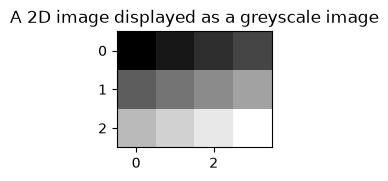

The 2D image as a matrix:
 [[  0  10  20  30]
 [ 40  50  60  70]
 [ 80  90 100 110]]

The 2D in computer memory:  [  0  10  20  30  40  50  60  70  80  90 100 110]


In [22]:
import matplotlib.pyplot as plt


image_2d = np.array([[0, 10, 20, 30], [40, 50, 60, 70], [80, 90, 100, 110]])
image_1d = image_2d.ravel()  # 'ravel()' return a contiguous flattened array.

fig, ax = plt.subplots(figsize=(2, 2))
ax.imshow(image_2d, cmap='gray')
plt.title("A 2D image displayed as a greyscale image")
plt.show()

print("The 2D image as a matrix:\n", image_2d)

print("\nThe 2D in computer memory: ", image_1d)

To lookup pixel values in this one dimensional array, we must calculate the index ourselves

In [24]:
h, w = image_2d.shape

for y in range(h):
    for x in range(w):
        i = y * w + x
        print(f"The pixel value at coordinate ({x}, {y}) = {image_1d[i]}")

The pixel value at coordinate (0, 0) = 0
The pixel value at coordinate (1, 0) = 10
The pixel value at coordinate (2, 0) = 20
The pixel value at coordinate (3, 0) = 30
The pixel value at coordinate (0, 1) = 40
The pixel value at coordinate (1, 1) = 50
The pixel value at coordinate (2, 1) = 60
The pixel value at coordinate (3, 1) = 70
The pixel value at coordinate (0, 2) = 80
The pixel value at coordinate (1, 2) = 90
The pixel value at coordinate (2, 2) = 100
The pixel value at coordinate (3, 2) = 110


## TODO:
### loop order
### out of bounds